Predicting energy of the au clusters with Gaussian regression

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
%pip install -q kagglehub
import kagglehub as khub
from pathlib import Path 


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
path = Path(khub.dataset_download("leewevml/energy-prediction-of-three-dimensional-clusters"))

In [5]:
files = sorted(p for p in path.rglob("*") if p.is_file())
print(path)
print(len(files), "files")
for f in files[:20]:
    print(f.relative_to(path))

/Users/mateolondono/.cache/kagglehub/datasets/leewevml/energy-prediction-of-three-dimensional-clusters/versions/3
4750 files
Coordinates and energies of clusters/Coordinates and energies of clusters/Au20_OPT_1000/0.xyz
Coordinates and energies of clusters/Coordinates and energies of clusters/Au20_OPT_1000/1.xyz
Coordinates and energies of clusters/Coordinates and energies of clusters/Au20_OPT_1000/10.xyz
Coordinates and energies of clusters/Coordinates and energies of clusters/Au20_OPT_1000/100.xyz
Coordinates and energies of clusters/Coordinates and energies of clusters/Au20_OPT_1000/101.xyz
Coordinates and energies of clusters/Coordinates and energies of clusters/Au20_OPT_1000/102.xyz
Coordinates and energies of clusters/Coordinates and energies of clusters/Au20_OPT_1000/103.xyz
Coordinates and energies of clusters/Coordinates and energies of clusters/Au20_OPT_1000/104.xyz
Coordinates and energies of clusters/Coordinates and energies of clusters/Au20_OPT_1000/105.xyz
Coordinates and 

In [6]:
# Visualizing one of the files
f = files[100]
print(f)
text = f.read_text()
print(text)

/Users/mateolondono/.cache/kagglehub/datasets/leewevml/energy-prediction-of-three-dimensional-clusters/versions/3/Coordinates and energies of clusters/Coordinates and energies of clusters/Au20_OPT_1000/19.xyz
20
-1549.039125
Au       1.30270910       1.30270905       1.39198420 
Au      -1.30270903      -1.30270908       1.39198417 
Au      -1.30270897       1.30270898       1.39198401 
Au       1.30270899      -1.30270898       1.39198403 
Au       2.94966372       2.94966372      -2.56450597 
Au      -2.94966372      -2.94966372      -2.56450596 
Au      -2.94966370       2.94966370      -2.56450594 
Au       2.94966371      -2.94966371      -2.56450596 
Au       2.94995956       2.94995956       2.56439540 
Au      -2.94995957      -2.94995957       2.56439541 
Au      -2.94995958       2.94995958       2.56439543 
Au       2.94995958      -2.94995958       2.56439542 
Au      -2.88038981      -2.88038981      -0.00008918 
Au       2.88038981       2.88038981      -0.00008917 
Au   

In [7]:
print(type(f))

<class 'pathlib.PosixPath'>


In [8]:
# Extract attomic coordinates and energy from files:
def extractor(file):

    try:
     type(file)=='pathlib.PosixPath'
    except NameError:
      print("Non path variable")

    lines = file.read_text().splitlines()

    n_atoms = int(lines[0])
    energy = float(lines[1])

    coords = np.array([
        list(map(float, line.split()[1:4]))
        for line in lines[2:2+n_atoms]
    ])

    return coords, energy



# Define the coulomb matrix
def C_matrix(f, Z):
    coords, energy = extractor(f)
    """ We define the Coulomb matrix for each cluster geometry"""

    N = len(coords)
    C_mat = np.zeros((N, N))

    # Diagonal elements
    for i in range(N):
        C_mat[i, i] = 0.5 * Z**2.4

    # Off-diagonal elements
    for i in range(N):
        for j in range(i + 1, N):
            r_ij = np.linalg.norm(coords[i] - coords[j])
            
            C_mat[i, j] = Z**2 / r_ij
            C_mat[j, i] = C_mat[i, j]

    # Eigenvalues
    eig = np.linalg.eigvalsh(C_mat)

    return C_mat, eig, energy


In [9]:
%pip install -q scikit-learn
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [10]:
#Save only data for Au
files_au = [x for x in files if "Au" in str(x)]

#Save the eigenvalue vectors and energies of each cluster
M_eig = np.zeros((1000,20),dtype=float)
Energies = np.zeros(1000)
for index,file in enumerate(files_au):
    C_m,eig,energy = C_matrix(file, 79)
    M_eig[index,:] = eig                   
    Energies[index]= energy

#Confirm sizes 
print(np.shape(M_eig))
print(np.shape(Energies))

#save as data_sets for exploring latter with pandas
np.savetxt("M_eig",M_eig)
np.savetxt("Energies", Energies)

(1000, 20)
(1000,)


In [11]:
# Read the data again as a dataset with pandas
X = pd.read_csv("../Au_clusters/M_eig",header=None,delim_whitespace=True)
Y = pd.read_csv("../Au_clusters/Energies",header=None,delim_whitespace=True)

#Verify is there are null values
Y.columns=['Au']
Y.sort_values(by=['Au'],ascending=True)

,Au
279,-1557.209460
782,-1556.299794
241,-1555.942377
946,-1555.942376
926,-1555.942374
...,...
594,-1538.870624
897,-1538.497324
754,-1530.908363
998,0.000000


In [12]:
#Get rid of null values
X.drop(index=998,inplace=True,axis=0)
Y.drop(index=998,inplace=True,axis=0)

X.drop(index=999,inplace=True,axis=0)
Y.drop(index=999,inplace=True,axis=0)
X.reset_index(drop=True,inplace=True)
Y.reset_index(drop=True,inplace=True)

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


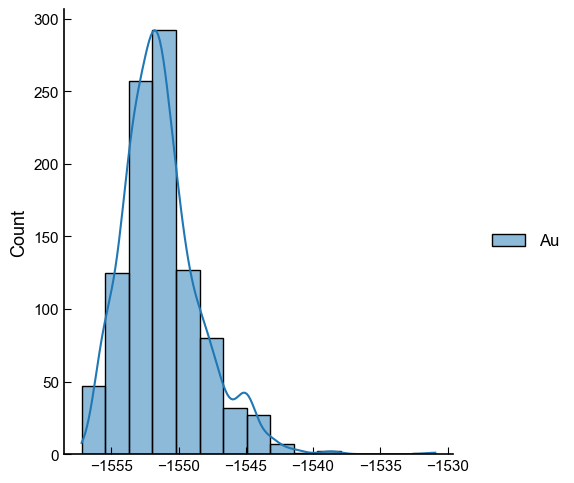

In [13]:
sns.displot(Y,bins=15,kde=True,label = 'count')


In [14]:
# Training the model and testing the model. 
X_np = X.to_numpy()
Y_np = Y["Au"].to_numpy()

X_train, X_test, Y_train, Y_test = train_test_split(X_np,Y_np,test_size=0.2,random_state=42)
print("train:", X_train.shape, "test:", X_test.shape)

print(X_train[5][:])

train: (798, 20) test: (200, 20)
[14752.64613076 14788.7486258  14788.74995771 14863.22382093
 14879.5233325  14879.53103506 14950.55545632 15102.27780816
 15171.98172759 15171.99690668 15207.43196283 15695.80221702
 16082.45519208 17355.28466628 17419.57203391 17419.62868951
 20992.23288083 20992.3158589  21307.27618675 46526.79369233]


In [15]:
# Scaling and defining kernel

kernel = (ConstantKernel(1.0, (1e-3, 1e3))
          * RBF(length_scale=np.ones(X_np.shape[1]), length_scale_bounds=(1e-2, 1e3))
          + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-8, 1e1)))

model = Pipeline([
    ("scaler", StandardScaler()),
    ("gpr", GaussianProcessRegressor(kernel=kernel, normalize_y=True,
                                     n_restarts_optimizer=3, random_state=42)),
])


In [16]:
# Training
model.fit(X_train, Y_train)
print("learned kernel:", model.named_steps["gpr"].kernel_)


learned kernel: 1.01**2 * RBF(length_scale=[4.73, 6.54, 4.62, 11.7, 4.78, 4.31, 4.75, 3.45, 2.43, 5.23, 2.54, 5.07, 6.1, 5.61, 31.9, 15.9, 3.53, 2.32, 2.22, 1.37]) + WhiteKernel(noise_level=3.88e-08)


MAE  = 0.3995
RMSE = 0.8020
R^2  = 0.9197
baseline MAE  = 2.1970


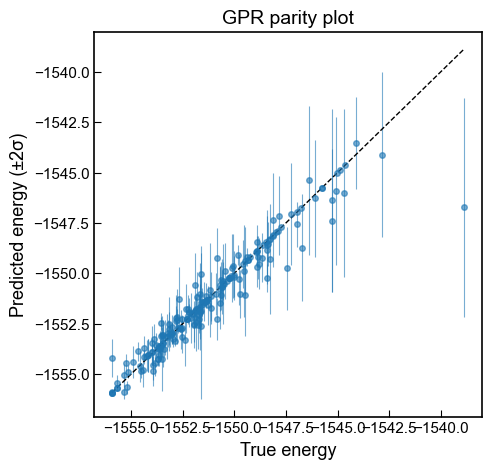

In [17]:
# Testing the model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Y_pred, Y_std = model.predict(X_test, return_std = True)

print(f"MAE  = {mean_absolute_error(Y_test, Y_pred):.4f}")
print(f"RMSE = {np.sqrt(mean_squared_error(Y_test, Y_pred)):.4f}")
print(f"R^2  = {r2_score(Y_test, Y_pred):.4f}")
print(f"baseline MAE  = {np.abs(Y_test - Y_train.mean()).mean():.4f}")

fig, ax = plt.subplots(figsize=(5,5))
ax.errorbar(Y_test,Y_pred, yerr=2*Y_std,fmt="o", ms=4, alpha=0.6,elinewidth=0.8)
lims = [Y_test.min(), Y_test.max()]
ax.plot(lims, lims, "k--", lw=1)

ax.set(xlabel="True energy", ylabel="Predicted energy (±2σ)", title="GPR parity plot")
plt.show()



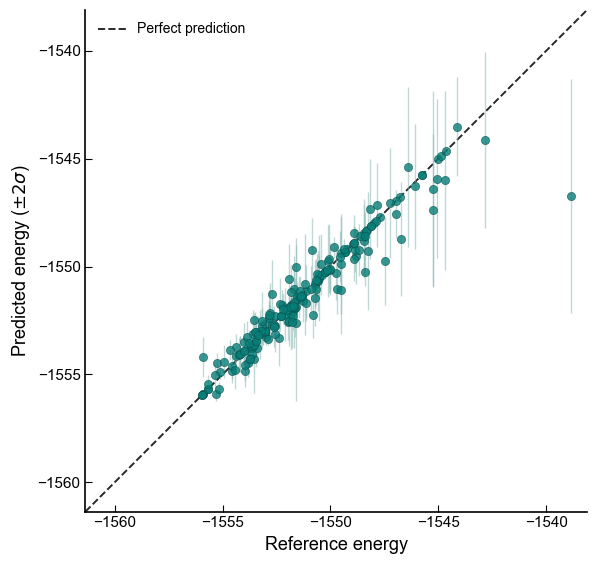

In [18]:
#Improving figures: 

import numpy as np
import matplotlib.pyplot as plt

# Publication-style settings
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 14,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 1.2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 5,
    "ytick.major.size": 5,
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

# Figure
fig, ax = plt.subplots(figsize=(6.2, 5.8))

# Prediction uncertainty
ax.errorbar(
    Y_test,
    Y_pred,
    yerr=2 * Y_std,
    fmt='none',
    ecolor='#8BB9B5',
    elinewidth=1.0,
    alpha=0.55,
    capsize=0,
    zorder=1
)

# Predictions
ax.scatter(
    Y_test,
    Y_pred,
    s=35,
    color='#087E78',
    edgecolor='#064E4A',
    linewidth=0.45,
    alpha=0.8,
    zorder=2
)

# Perfect prediction line
emin = min(Y_test.min(), Y_pred.min() - 2*Y_std.max())
emax = max(Y_test.max(), Y_pred.max() + 2*Y_std.max())

ax.plot(
    [emin, emax],
    [emin, emax],
    linestyle='--',
    color='#292929',
    linewidth=1.4,
    label='Perfect prediction',
    zorder=0
)

# Axes
ax.set_xlim(emin, emax)
ax.set_ylim(emin, emax)
ax.set_aspect('equal', adjustable='box')

ax.set_xlabel(r'Reference energy')
ax.set_ylabel(r'Predicted energy ($\pm 2\sigma$)')

# Remove top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend(
    frameon=False,
    loc='upper left',
    fontsize=10
)

ax.tick_params(which='both', top=False, right=False)

plt.tight_layout()
plt.savefig(
    'GPR_parity_plot.png',
    dpi=500,
    bbox_inches='tight'
)
plt.show()


In [23]:
# Now we peerformed a 5-fold cross validation
from sklearn.model_selection import KFold, cross_validate
cv =cross_validate(model,X_np,Y_np, cv=KFold(5, shuffle=True,random_state=42),
                   scoring = ("neg_mean_absolute_error","r2"))
print(f"MAE = {-cv['test_neg_mean_absolute_error'].mean():.4f} ± {cv['test_neg_mean_absolute_error'].std():.4f}")
print(f"R^2 = {cv['test_r2'].mean():.4f} ± {cv['test_r2'].std():.4f}")

MAE = 0.4310 ± 0.0258
R^2 = 0.8859 ± 0.0699


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 14 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


In [153]:
# Identifying the ten worst predictions in the model

errors = Y_test - Y_pred
worst = np.argsort(np.abs(errors))[-10:][::-1]
results = pd.DataFrame({
    "True energy": Y_test[worst],
    "Predicted energy": Y_pred[worst],
    "Error": errors[worst],
    "Uncertainty": Y_std[worst]
})

print(results)


   True energy  Predicted energy     Error  Uncertainty
0 -1538.870624      -1546.732169  7.861545     2.709703
1 -1547.468634      -1549.746554  2.277920     1.029304
2 -1545.269752      -1547.382144  2.112392     1.772632
3 -1546.717161      -1548.726674  2.009513     1.321858
4 -1548.409178      -1550.232461  1.823283     0.338828
5 -1555.924234      -1554.205214 -1.719020     0.466396
6 -1550.846070      -1549.233443 -1.612627     0.750366
7 -1549.494430      -1551.081035  1.586605     1.025422
8 -1551.598211      -1550.034834 -1.563377     0.683664
9 -1552.692840      -1551.259847 -1.432993     0.788055
